# Снижение активности по картам: кто, насколько и за счёт чего

**Автор:** Лапицкий Михаил Станиславович
**Период данных:** 2024-01-01 — 2025-06-30
**Подготовлено для:** департамент розничных продуктов, банк «Меридиан»

<!--
Этот ноутбук собирается в HTML командой:
jupyter nbconvert --to html --no-input --execute 02_report.ipynb --output report.html

Поэтому: кода читатель не видит, все графики и таблицы получены
исполнением, числа в тексте должны совпадать с выводом кода.
Лимит: 6 страниц и 8 графиков.
-->


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display

clients = pd.read_parquet("clients_clean.parquet")
transactions = pd.read_parquet("transactions_clean.parquet")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7.2, 2.0)
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["font.size"] = 10

opened = clients["card_open_date"].dt.to_period("M").dt.to_timestamp()


def open_months(opened, start, end):
    left = opened.where(opened > start, start)
    months = (end.year - left.dt.year) * 12 + (end.month - left.dt.month) + 1
    return months.where(opened <= end, 0).astype(int)


rub = transactions.loc[
    (transactions["status"] == "успешно")
    & (transactions["amount"] > 0)
    & (transactions["currency"] == "RUB")
].copy()
rub["month"] = rub["txn_datetime"].dt.to_period("M").dt.to_timestamp()


def window_values(start, end, agg):
    part = rub.loc[(rub["month"] >= start) & (rub["month"] <= end)]
    if agg == "sum":
        return part.groupby("client_id")["amount"].sum()
    return part.groupby("client_id").size()


activity = clients[["client_id"]].copy()
activity["base_months"] = open_months(opened, pd.Timestamp("2024-01-01"), pd.Timestamp("2024-12-01"))
activity["eval_months"] = open_months(opened, pd.Timestamp("2025-01-01"), pd.Timestamp("2025-06-01"))
activity["base_sum"] = activity["client_id"].map(window_values("2024-01-01", "2024-12-01", "sum")).fillna(0)
activity["eval_sum"] = activity["client_id"].map(window_values("2025-01-01", "2025-06-01", "sum")).fillna(0)
activity["base_n"] = activity["client_id"].map(window_values("2024-01-01", "2024-12-01", "count")).fillna(0)
activity["eval_n"] = activity["client_id"].map(window_values("2025-01-01", "2025-06-01", "count")).fillna(0)
activity["base_rate"] = activity["base_sum"] / activity["base_months"].replace(0, np.nan)
activity["eval_rate"] = activity["eval_sum"] / activity["eval_months"].replace(0, np.nan)
activity["base_n_rate"] = activity["base_n"] / activity["base_months"].replace(0, np.nan)
activity["eval_n_rate"] = activity["eval_n"] / activity["eval_months"].replace(0, np.nan)

work = clients.merge(activity, on="client_id")
work["change"] = work["eval_rate"] / work["base_rate"] - 1
work["n_change"] = work["eval_n_rate"] / work["base_n_rate"] - 1
work["lost"] = (work["base_rate"] - work["eval_rate"]) * work["eval_months"]

observed = ~work["income_imputed"] & ~work["false_income"]
work["income_group"] = "доход подставлен"
work.loc[observed, "income_group"] = pd.cut(
    work.loc[observed, "monthly_income"],
    [0, 50000, 100000, 200000, np.inf],
    labels=["до 50 тыс.", "50–100 тыс.", "100–200 тыс.", "свыше 200 тыс."],
    right=False,
).astype(str)

ready = work["marketing_opt_in"].eq("Да") & work["base_months"].eq(12) & work["base_rate"].gt(0)
fell = ready & work["change"].le(-0.2)
rich = (
    work["income_group"].isin(["100–200 тыс.", "свыше 200 тыс."])
    | work["segment"].isin(["Премиальный", "Private"])
)
loyal = work["loyalty_tier"].isin(["Золото", "Платина"])
high_spend = work["base_rate"].ge(15000)
mass_no_app = work["segment"].eq("Массовый") & work["has_mobile_app"].eq("Нет")

work["group"] = pd.NA
work.loc[fell & mass_no_app, "group"] = "массовый без приложения"
work.loc[fell & high_spend, "group"] = "трата от 15 тыс. в месяц"
work.loc[fell & loyal, "group"] = "золото или платина"
work.loc[fell & rich, "group"] = "доход от 100 тыс. или верхний сегмент"


## 1. Главное

<!-- 3–5 выводов с числами. Пишется последним, читается первым.
     Каждый вывод — утверждение, а не тема. Не «анализ активности»,
     а «активность упала на X% у группы Y за счёт Z». -->

1. Год к году траты по картам ниже. У 4827 клиентов, чья карта открыта до 2024 года, средняя сумма трат в месяц была 13308 рублей в 2024 году и 10106 рублей в январе–июне 2025 года, на 24,1% меньше. У типичного такого клиента сумма в месяц ниже на 33%, а число покупок — на 19%. По всему банку за средний месяц прошло 64,7 млн рублей в 2024 году и 51,3 млн в январе–июне 2025, на 20,7% меньше.
2. У клиентов с премиальным обслуживанием снижение слабее, чем у массового сегмента. Массовый сегмент, 2578 человек: траты в месяц ниже на 36,3%. Зарплатный, 1294 человека: на 19,6%. Private, 207 человек: на 16,2%. Премиальный сегмент, 735 человек: на 13,8%.
3. Спад не из-за того, что клиенты ушли, и не из-за того, что банк стал чаще отклонять операции. В январе 2025 года оплату провели 4787 клиентов, в январе 2024 года — 4640. Доля отклонённых операций — 0,020 в 2024 году и 0,019 в 2025. Через год после открытия карты человек тратит около 12747 рублей в месяц, через пять лет — около 11941: со временем карта не перестаёт использоваться.


## 2. Контекст

<!-- Какое решение поддерживает этот отчёт, 3–5 предложений. -->

Департамент розничных продуктов видит, что за январь–июнь 2025 клиенты реже пользуются картами, и готовит кампанию по возврату активности. Бюджет — не больше 2000 клиентов. Нужны 3–5 групп от 150 человек, у каждой своё правило и своя коммуникация. Писать можно только тем, кто дал согласие. Отчёт говорит, кому писать и чем группы отличаются по характеру спада.


## 3. Данные и ограничения

<!-- Период, число клиентов и операций, что и почему исключено из расчёта,
     чего в данных нет.

     Здесь же одним абзацем: какую метрику активности вы выбрали,
     как она считается и какое снижение она не увидит. -->

База для сравнения — весь 2024 год, оценка — январь–июнь 2025. Шесть клиентов без операций в справочнике оставлены. В данных нет цены и количества в чеке и нет конкретного магазина: есть только тип точки, таких типов девять. Нет числа входов в приложение по месяцам, есть месяц последнего входа.

Сравниваем, сколько рублей в месяц клиент тратит по карте. Берём оплаты, которые прошли, в рублях и с положительной суммой, и делим на число месяцев, когда карта уже была открыта. Месяц открытия учитываем. В 2024 году таких месяцев до двенадцати, в январе–июне 2025 — до шести, поэтому сравниваем сумму в месяц, а не сумму за весь период. Если карта открыта только в 2025 году, сравнивать не с чем.

Эта мера не замечает клиента, который стал платить реже, но на ту же сумму в месяц: таких со старой картой 252 человека. Отклонённые операции и возвраты в сумму не входят.


In [2]:
full = work["base_months"].eq(12)
base_mean = work.loc[full, "base_rate"].mean()
eval_mean = work.loc[full, "eval_rate"].mean()
succ = transactions.loc[transactions["status"].eq("успешно")]
count_down = (work.loc[full, "n_change"] < -0.2) & (work.loc[full, "change"] >= -0.2)
pct = abs(round((eval_mean / base_mean - 1) * 100, 1))
sum_drop = abs(round(work.loc[full, "change"].median() * 100))
n_drop = abs(round(work.loc[full, "n_change"].median() * 100))
print(f"В справочнике {len(clients)} клиентов. Операций за 2024 год и январь–июнь 2025 — {len(transactions)}.")
print(
    f"Пустой доход заполнен у {int(clients['income_imputed'].sum())} клиентов, "
    f"доход не выше 1000 рублей заменён у {int(clients['false_income'].sum())}. "
    "В разрезы по доходу они не входят."
)
print(
    f"Оценку поставили {int(clients['satisfaction_score'].notna().sum())} клиентов. "
    f"Отделений {int(clients['branch_code'].nunique())}, "
    f"в самом большом {int(clients['branch_code'].value_counts().max())} клиентов."
)
print(
    f"Оплат не в рублях {int(succ['currency'].ne('RUB').sum())} из {len(succ)}. "
    "В сравнение трат они не входят."
)
print(
    f"У {int(full.sum())} клиентов карта открыта до 2024 года. "
    f"В среднем они тратили {round(base_mean)} рублей в месяц в 2024 году "
    f"и {round(eval_mean)} рублей в январе–июне 2025, на {str(pct).replace('.', ',')}% меньше."
)
print(
    f"У типичного такого клиента сумма в месяц ниже на {sum_drop}%, число покупок — на {n_drop}%."
)


В справочнике 5626 клиентов. Операций за 2024 год и январь–июнь 2025 — 593270.
Пустой доход заполнен у 555 клиентов, доход не выше 1000 рублей заменён у 206. В разрезы по доходу они не входят.
Оценку поставили 2297 клиентов. Отделений 840, в самом большом 17 клиентов.
Оплат не в рублях 2280 из 574614. В сравнение трат они не входят.
У 4827 клиентов карта открыта до 2024 года. В среднем они тратили 13308 рублей в месяц в 2024 году и 10106 рублей в январе–июне 2025, на 24,1% меньше.
У типичного такого клиента сумма в месяц ниже на 33%, число покупок — на 19%.


## 4. Находки


### 4.1. Сумма рублей ниже января 2024 и к июню не вернулась к обычному месяцу


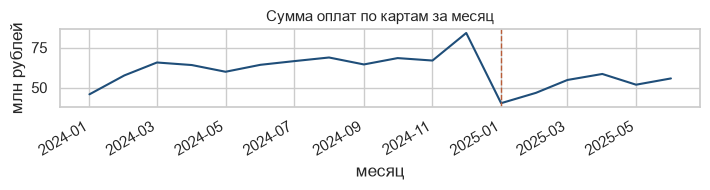

средний месяц 2024, млн руб. 64.7
средний месяц янв–июн 2025, млн руб. 51.3
изменение суммы, % -20.7
январь 2025 к январю 2024, % 87.9
июнь 2025 к среднему месяцу 2024, % 86.1


In [3]:
monthly = (
    rub.groupby("month")
    .agg(рубли=("amount", "sum"), операции=("amount", "size"), клиенты=("client_id", "nunique"))
    .sort_index()
)
monthly["чек"] = monthly["рубли"] / monthly["операции"]
year = monthly.loc[monthly.index < "2025-01-01"]
half = monthly.loc[monthly.index >= "2025-01-01"]

fig, ax = plt.subplots()
ax.plot(monthly.index, monthly["рубли"] / 1e6, color="#1f4e79")
ax.axvline(pd.Timestamp("2025-01-01"), color="#b85c38", linestyle="--", linewidth=1)
ax.set_ylabel("млн рублей")
ax.set_xlabel("месяц")
ax.set_title("Сумма оплат по картам за месяц")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

print("средний месяц 2024, млн руб.", round(year["рубли"].mean() / 1e6, 1))
print("средний месяц янв–июн 2025, млн руб.", round(half["рубли"].mean() / 1e6, 1))
print("изменение суммы, %", round((half["рубли"].mean() / year["рубли"].mean() - 1) * 100, 1))
print("январь 2025 к январю 2024, %", round(monthly.loc["2025-01-01", "рубли"] / monthly.loc["2024-01-01", "рубли"] * 100, 1))
print("июнь 2025 к среднему месяцу 2024, %", round(monthly.loc["2025-06-01", "рубли"] / year["рубли"].mean() * 100, 1))


В среднем за месяц в 2024 году клиенты оплатили картами 64,7 млн рублей, в январе–июне 2025 года — 51,3 млн, на 20,7% меньше. В декабре 2024 года было 84,2 млн. В январе 2025 года — 40,2 млн, это 87,9% января 2024 года (45,8 млн). В июне 2025 года — 55,7 млн, 86,1% обычного месяца 2024 года. В январе 2025 года платили 4787 клиентов, в январе 2024 года — 4640. Средняя сумма одной оплаты в эти январи — 1914 и 1791 рубль.


### 4.2. У массового сегмента спад суммы трат сильнее, чем у премиального


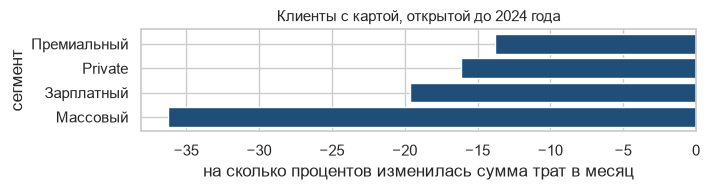

,клиенты,рубли_2024,рубли_2025,"сумма трат в месяц, %"
segment,,,,
Массовый,2578,9290.0,5921.0,-36.3
Зарплатный,1294,13625.0,10949.0,-19.6
Private,207,30569.0,25629.0,-16.2
Премиальный,735,21965.0,18937.0,-13.8


Без приложения: 1858 клиентов, сумма трат в месяц ниже на 31.5%. С приложением: 2969 клиентов, ниже на 19.7%.


In [5]:
full = work["base_months"].eq(12)
seg = (
    work.loc[full & work["segment"].ne("Неопределено")]
    .groupby("segment")
    .agg(клиенты=("client_id", "size"), рубли_2024=("base_rate", "mean"), рубли_2025=("eval_rate", "mean"))
)
seg["изменение, %"] = (seg["рубли_2025"] / seg["рубли_2024"] - 1) * 100
seg = seg.sort_values("изменение, %")

fig, ax = plt.subplots()
ax.barh(seg.index, seg["изменение, %"], color="#1f4e79")
ax.set_xlabel("на сколько процентов изменилась сумма трат в месяц")
ax.set_ylabel("сегмент")
ax.set_title("Клиенты с картой, открытой до 2024 года")
fig.tight_layout()
plt.show()

shown = seg.copy()
shown["рубли_2024"] = shown["рубли_2024"].round(0)
shown["рубли_2025"] = shown["рубли_2025"].round(0)
shown["изменение, %"] = shown["изменение, %"].round(1)
shown = shown.rename(columns={"изменение, %": "сумма трат в месяц, %"})
display(shown)

app = (
    work.loc[full]
    .groupby("has_mobile_app")
    .agg(клиенты=("client_id", "size"), рубли_2024=("base_rate", "mean"), рубли_2025=("eval_rate", "mean"))
)
app["изменение, %"] = ((app["рубли_2025"] / app["рубли_2024"] - 1) * 100).round(1)
app["рубли_2024"] = app["рубли_2024"].round(0)
app["рубли_2025"] = app["рубли_2025"].round(0)
app = app.rename(columns={"изменение, %": "сумма трат в месяц, %"})
no_app = app.loc["Нет"]
yes_app = app.loc["Да"]
print(
    f"Без приложения: {int(no_app['клиенты'])} клиентов, сумма трат в месяц ниже на {abs(no_app['сумма трат в месяц, %'])}%. "
    f"С приложением: {int(yes_app['клиенты'])} клиентов, ниже на {abs(yes_app['сумма трат в месяц, %'])}%."
)


На графике клиенты, чья карта открыта до 2024 года. Сегмент «Неопределено» не показан. Массовый сегмент: 2578 человек, траты в месяц ниже на 36,3%. Зарплатный: 1294 человека, на 19,6%. Private: 207 человек, на 16,2%. Премиальный: 735 человек, на 13,8%.


### 4.3. Средняя сумма одной оплаты ниже в каждой категории, состав покупок почти не сдвинулся


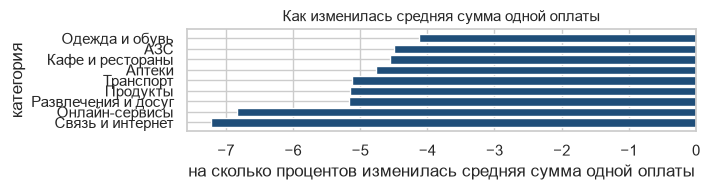

средний чек 2024 1922.6
средний чек 2025 1828.6
разница, руб. -94.1
за счёт долей категорий, руб. -2.6
внутри категорий, руб. -91.5
медиана 2024 1114
медиана 2025 1026
category
Связь и интернет      -7.2
Онлайн-сервисы        -6.8
Развлечения и досуг   -5.2
Продукты              -5.1
Транспорт             -5.1
Аптеки                -4.8
Кафе и рестораны      -4.6
АЗС                   -4.5
Одежда и обувь        -4.1


In [6]:
ok = rub.copy()
ok["period"] = np.where(ok["month"] < "2025-01-01", "2024", "2025")
means = ok.groupby(["period", "category"])["amount"].mean().unstack()
share = ok.groupby(["period", "category"]).size().unstack()
share = share.div(share.sum(axis=1), axis=0)
base_mean = ok.loc[ok["period"].eq("2024"), "amount"].mean()
later_mean = ok.loc[ok["period"].eq("2025"), "amount"].mean()
cat_base = ok.loc[ok["period"].eq("2024")].groupby("category")["amount"].mean()
mix = (share.loc["2025"] * cat_base).sum() - (share.loc["2024"] * cat_base).sum()
within = (later_mean - base_mean) - mix
ticket_chg = ((means.loc["2025"] - means.loc["2024"]) / means.loc["2024"] * 100).sort_values()

fig, ax = plt.subplots()
ax.barh(ticket_chg.index, ticket_chg.values, color="#1f4e79")
ax.set_xlabel("на сколько процентов изменилась средняя сумма одной оплаты")
ax.set_ylabel("категория")
ax.set_title("Как изменилась средняя сумма одной оплаты")
fig.tight_layout()
plt.show()

print("средний чек 2024", round(base_mean, 1))
print("средний чек 2025", round(later_mean, 1))
print("разница, руб.", round(later_mean - base_mean, 1))
print("за счёт долей категорий, руб.", round(mix, 1))
print("внутри категорий, руб.", round(within, 1))
print("медиана 2024", round(ok.loc[ok["period"].eq("2024"), "amount"].median()))
print("медиана 2025", round(ok.loc[ok["period"].eq("2025"), "amount"].median()))
print(ticket_chg.round(1).to_string())


Средняя сумма одной оплаты — 1922,6 рубля в 2024 году и 1828,6 в январе–июне 2025, на 94,1 рубля меньше. Половина оплат была не выше 1114 рублей, стала не выше 1026. Почти вся разница, 91,5 рубля из 94,1, приходится на то, что покупка стала меньше внутри той же категории. На смену самих категорий приходится 2,6 рубля. Сильнее всего средняя оплата снизилась у связи, на 7,2%, слабее всего у одежды, на 4,1%.


## 5. Группы для кампании

<!-- Таблица: группа, правило отбора, размер, причина падения.
     Ниже — по абзацу на группу. -->


In [7]:
order = [
    "доход от 100 тыс. или верхний сегмент",
    "золото или платина",
    "трата от 15 тыс. в месяц",
    "массовый без приложения",
]
rules = {
    "доход от 100 тыс. или верхний сегмент": "доход от 100 тыс. или сегмент Премиальный / Private",
    "золото или платина": "лояльность Золото или Платина",
    "трата от 15 тыс. в месяц": "в 2024 от 15 000 рублей в месяц",
    "массовый без приложения": "сегмент Массовый и приложения нет",
}
rows = []
for name in order:
    part = work.loc[work["group"].eq(name)]
    rows.append(
        {
            "группа": name,
            "кто": rules[name],
            "человек": len(part),
            "рубли, %": round(part["change"].median() * 100),
            "операции, %": round(part["n_change"].median() * 100),
            "недобор, млн руб.": round(part["lost"].sum() / 1e6, 1),
        }
    )
display(pd.DataFrame(rows))
chosen = work["group"].notna()
print("в списке", int(chosen.sum()), "разных", int(work.loc[chosen, "client_id"].nunique()))
raw = pd.DataFrame(
    {
        "доход или сегмент": fell & rich,
        "лояльность": fell & loyal,
        "трата": fell & high_spend,
        "массовый без приложения": fell & mass_no_app,
    }
)
print("под два правила и больше", int(raw.sum(axis=1).ge(2).sum()))
upper_only = fell & work["segment"].isin(["Премиальный", "Private"]) & ~work["income_group"].isin(
    ["100–200 тыс.", "свыше 200 тыс."]
)
print("верхний сегмент без дохода от 100 тыс.", int(upper_only.sum()))


,группа,кто,человек,"рубли, %","операции, %","недобор, млн руб."
0,доход от 100 тыс. или верхний сегмент,доход от 100 тыс. или сегмент Премиальный / Pr...,708,-48,-31,39.7
1,золото или платина,лояльность Золото или Платина,172,-55,-30,6.4
2,трата от 15 тыс. в месяц,в 2024 от 15 000 рублей в месяц,309,-56,-31,21.4
3,массовый без приложения,сегмент Массовый и приложения нет,528,-67,-64,15.3


в списке 1717 разных 1717
под два правила и больше 661
верхний сегмент без дохода от 100 тыс. 103


В список входят клиенты с согласием на сообщения банка, с картой, открытой до 2024 года, у которых сумма трат в месяц ниже на 20% или больше. Если человек подходит под несколько правил, остаётся то, которое выше в таблице. До этого отбора таких 661 человек. В списке 1717 разных клиентов. Премиальный сегмент и Private без дохода от 100 тыс. — 103 человека, отдельную группу из них не делаем.

Доход от 100 тыс. рублей или сегмент Премиальный / Private: 708 человек. Сумма в месяц ниже на 48%, число покупок — на 31%. Недобор за январь–июнь 2025 — 39,7 млн рублей.

Золото или платина, кто не попал выше: 172 человека. Сумма ниже на 55%, покупок — на 30%. Недобор 6,4 млн рублей.

В 2024 году тратили от 15 000 рублей в месяц и не попали выше: 309 человек. Сумма ниже на 56%, покупок — на 31%. Недобор 21,4 млн рублей.

Массовый сегмент без приложения: 528 человек. Сумма ниже на 67%, покупок — на 64%. Недобор 15,3 млн рублей. Здесь люди стали платить реже почти настолько же, насколько упала сумма. В трёх остальных группах покупок меньше примерно на 30%, а сумма — на 48–56%.


## 6. Кого не включаем и почему

<!-- Отдельным списком. Для каждой категории: кто это, сколько их,
     почему кампания им не нужна или бесполезна. -->


In [8]:
excluded = pd.DataFrame(
    [
        ["нет согласия на связь", int(work["marketing_opt_in"].eq("Нет").sum()), "писать нельзя"],
        ["карта открыта в 2025", int(work["base_months"].eq(0).sum()), "нет рублей в месяц за 2024"],
        ["карта открыта в течение 2024", int(work["base_months"].between(1, 11).sum()), "в базовом окне не 12 месяцев"],
        ["согласие есть, карта весь 2024, падение меньше 20%", int((ready & ~fell).sum()), "спад слабее порога"],
        ["падение от 20%, под четыре правила не попали", int((fell & work["group"].isna()).sum()), "отдельной группы от 150 человек нет"],
    ],
    columns=["кто", "человек", "почему не в списке"],
)
display(excluded)


,кто,человек,почему не в списке
0,нет согласия на связь,636,писать нельзя
1,карта открыта в 2025,374,нет рублей в месяц за 2024
2,карта открыта в течение 2024,425,в базовом окне не 12 месяцев
3,"согласие есть, карта весь 2024, падение меньше...",1690,спад слабее порога
4,"падение от 20%, под четыре правила не попали",880,отдельной группы от 150 человек нет


## 7. Что проверили и что не подтвердилось

<!-- 3–5 строк, по одной на гипотезу, каждая с числом. -->


In [9]:
flow = transactions.copy()
flow["period"] = np.where(flow["txn_datetime"] < "2025-01-01", "2024", "2025")
share = flow.groupby("period")["status"].value_counts(normalize=True).unstack()

months = pd.date_range("2024-01-01", "2025-06-01", freq="MS")
grid = clients[["client_id", "card_open_date"]].copy()
grid["open_m"] = grid["card_open_date"].dt.to_period("M").dt.to_timestamp()
grid = grid.assign(key=1).merge(pd.DataFrame({"month": months, "key": 1}), on="key")
grid["tenure"] = (
    (grid["month"].dt.year - grid["open_m"].dt.year) * 12
    + (grid["month"].dt.month - grid["open_m"].dt.month)
)
grid = grid.loc[grid["tenure"] >= 0]
exposed = grid.groupby("tenure")["client_id"].nunique()
life = rub.merge(clients[["client_id", "card_open_date"]], on="client_id")
life["open_m"] = life["card_open_date"].dt.to_period("M").dt.to_timestamp()
life["tenure"] = (
    (life["month"].dt.year - life["open_m"].dt.year) * 12
    + (life["month"].dt.month - life["open_m"].dt.month)
)
life = life.loc[life["tenure"] >= 0]
ops = life.groupby("tenure").size()
money = life.groupby("tenure")["amount"].sum()

mcc = rub.groupby(["month", "mcc_code"])["amount"].sum().unstack().fillna(0)
base = mcc.loc[mcc.index < "2025-01-01"].mean()
later = mcc.loc[mcc.index >= "2025-01-01"].mean()
worst = ((later - base) / base).min()
login = clients.loc[clients["app_last_login"].notna(), "app_last_login"].dt.to_period("M").value_counts()

print(
    f"Срок карты спад не объясняет: через год после открытия "
    f"{round(ops.loc[12] / exposed.loc[12], 1)} операции и {round(money.loc[12] / exposed.loc[12])} рублей в месяц, "
    f"через пять лет — {round(ops.loc[60] / exposed.loc[60], 1)} операции и {round(money.loc[60] / exposed.loc[60])} рублей."
)
print(
    f"Доля отклонённых операций {share.loc['2024', 'отклонено']:.3f} в 2024 году "
    f"и {share.loc['2025', 'отклонено']:.3f} в 2025."
)
print(
    f"Типов магазинов {int(mcc.shape[1])}, сильнее всего сумма снизилась на {round(abs(worst) * 100)}%."
)
print(
    f"Последний вход в приложение: от {int(login.min())} до {int(login.max())} клиентов в месяц."
)


Срок карты спад не объясняет: через год после открытия 6.7 операции и 12747 рублей в месяц, через пять лет — 6.3 операции и 11941 рублей.
Доля отклонённых операций 0.020 в 2024 году и 0.019 в 2025.
Типов магазинов 9, сильнее всего сумма снизилась на 36%.
Последний вход в приложение: от 155 до 223 клиентов в месяц.


## 8. Приложение

### 8.1. Сводка журнала изменений

<!-- 5–10 строк по типам нарушений: поле, что найдено, сколько строк,
     что сделано. Полный журнал — в cleaning_log.csv. -->

Ниже поле, что найдено, сколько строк и что сделано. Полный журнал в `cleaning_log.csv`.


In [10]:
log = pd.read_csv("cleaning_log.csv")

def rows(text):
    return int(log.loc[log["issue"].str.contains(text, regex=False), "n_rows"].iloc[0])

print(f"Полные копии клиентов удалены: {rows('полная копия')} строк. После правки города и сегмента удалены ещё {rows('строки одного id')} лишних строк.")
print(f"Повтор идентификатора операции удалён: {rows('повтор идентификатора')} строк.")
print(f"Написания городов сведены: {rows('17 написаний')} строк. У {rows('разные города')} строк город так и различался, поставлено «Неопределено».")
print(f"Лишние написания категорий исправлены: {rows('три лишних')} строк. Разный сегмент у одного клиента: {rows('разные сегменты')} строк, поставлено «Неопределено».")
print(f"Пустой доход заполнен у {rows('пропуск дохода')} клиентов, доход не выше 1000 рублей заменён у {rows('доход не выше 1000')}. Медиана 75000.")
print(f"Операции без клиента удалены: {rows('операция без клиента')}. Вне окна 2024-01-01 … 2025-06-30 удалены: {rows('дата вне окна')}.")
print(f"Оставлены пустой вход в приложение, {rows('пустая дата входа')} клиентов, и пустая оценка, {rows('пустая оценка')} клиентов.")
print(f"Оставлены отрицательные суммы, {rows('отрицательная сумма')} строк: это возвраты. Шесть клиентов без операций в справочнике оставлены.")


Полные копии клиентов удалены: 40 строк. После правки города и сегмента удалены ещё 15 лишних строк.
Повтор идентификатора операции удалён: 1500 строк.
Написания городов сведены: 1603 строк. У 24 строк город так и различался, поставлено «Неопределено».
Лишние написания категорий исправлены: 51939 строк. Разный сегмент у одного клиента: 28 строк, поставлено «Неопределено».
Пустой доход заполнен у 555 клиентов, доход не выше 1000 рублей заменён у 206. Медиана 75000.
Операции без клиента удалены: 31093. Вне окна 2024-01-01 … 2025-06-30 удалены: 95.
Оставлены пустой вход в приложение, 2151 клиентов, и пустая оценка, 3329 клиентов.
Оставлены отрицательные суммы, 7448 строк: это возвраты. Шесть клиентов без операций в справочнике оставлены.


### 8.2. Методика

<!-- Точные формулы, фильтры, пороги и их значения. Всё, что нужно,
     чтобы повторить расчёт. -->

В сумму входят оплаты со статусом «успешно», с суммой больше нуля, в рублях. База — январь–декабрь 2024. Сравнение — январь–июнь 2025.

Месяцы карты в окне считаются от месяца открытия, если он внутри окна, до конца окна, оба конца входят. Если карта открыта после конца окна, месяцев 0. Рубли в месяц = сумма окна / это число. Изменение = значение 2025 / значение 2024 − 1. Недобор группы = сумма по клиентам (рубли в месяц 2024 − рубли в месяц 2025) × месяцы карты в 2025.

В группы входят клиенты с согласием на связь, с 12 месяцами в 2024 и с тратами в 2024 году, у которых сумма в месяц ниже на 20% или больше. Если подходят несколько правил, остаётся более раннее: доход от 100 тыс. или сегмент Премиальный / Private, затем золото или платина, затем трата от 15 000 рублей в месяц, затем массовый сегмент без приложения. Доход от 100 тыс. — наблюдаемый доход в корзинах «100–200 тыс.» и «свыше 200 тыс.». Подставленный доход туда не входит. Медиана для заполнения пустого и ошибочного дохода — 75000, она посчитана по доходам выше 1000 рублей.

Средняя сумма одной оплаты считается по тем же оплатам. Вклад смены категорий: доли категорий в 2025 году, умноженные на среднюю сумму этой категории в 2024, минус то же для долей 2024 года. Остаток разницы — изменение внутри категорий.


### 8.3. Использование ИИ

<!-- 3–5 строк: для чего использовали и что проверили сами. -->

ИИ помогал разбирать задание, предлагать черновики кода и короткие пояснения.
Сам проверял, что код делает с данными: дубли, пропуски, период, метрику активности и состав групп.
В отчёт попали числа из пересчёта по очищенным данным, а не из ответа ассистента.
